# D3: Perceptron Training — XOR and Visualisation

**FIT1061 Introduction to Artificial Intelligence — Distinction Task 3**

At PASS level (P8) you computed weighted sums with *fixed* weights and visualised the decision boundary. The interesting question is: *where do the weights come from?* In 1958 Frank Rosenblatt published the **perceptron learning algorithm** — a recipe for finding weights from labelled examples by making small corrections every time the model gets a prediction wrong.

In this task you:

1. Implement the perceptron update rule.
2. Train it on a linearly separable dataset and watch the decision boundary move into place across epochs.
3. Run it on XOR and discover that it **cannot converge** — and explain *why* geometrically.

> **Prerequisite:** P8 (Ready for Feedback). You'll reuse weighted-sum prediction and the `w · x + b` decision rule.

> **Distinction level:** Less scaffolding. We provide the data and plotting helpers. You write the update rule, the training loop, the experiments, and the geometric write-up.

> **Notation:** Labels are in `{-1, +1}` (same as P8). The prediction is `ŷ = sign(w · x + b)`. With labels in `{-1, +1}`, the update term `(y - ŷ)` is `0` when correct and `±2` when wrong. We use a small **bias trick** in the update: the bias `b` updates at the same time as the weights but with no input feature.

---

## Setup

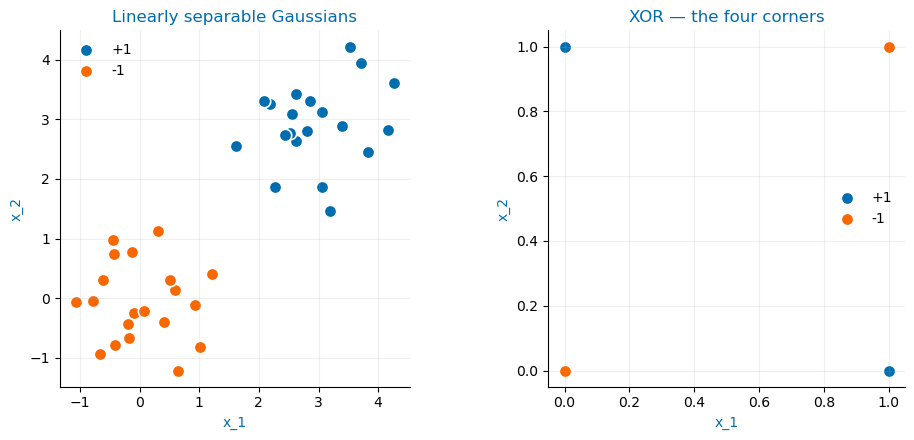

Separable: 40 points
XOR:       4 points


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random

from d3_helpers import (
    SEPARABLE_POINTS, SEPARABLE_LABELS,
    XOR_POINTS, XOR_LABELS,
    plot_data, plot_boundary, plot_boundary_evolution, plot_learning_curve,
    sign, accuracy,
)

# A look at the two datasets.
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
plot_data(SEPARABLE_POINTS, SEPARABLE_LABELS, title="Linearly separable Gaussians",
          ax=axes[0])
plot_data(XOR_POINTS, XOR_LABELS, title="XOR — the four corners", ax=axes[1])
plt.tight_layout()
plt.show()

print(f"Separable: {SEPARABLE_POINTS.shape[0]} points")
print(f"XOR:       {XOR_POINTS.shape[0]} points")

---

## D3.1: Implement the perceptron update

You already know the prediction rule from P8:

$$\hat{y} = \text{sign}(\mathbf{w} \cdot \mathbf{x} + b)$$

The **update rule** is what's new. Given a training example $(\mathbf{x}_i, y_i)$ and the current prediction $\hat{y}_i$:

- If the prediction is correct ($\hat{y}_i = y_i$): do nothing.
- If the prediction is wrong: adjust the weights toward the correct label.

The standard rule is:

$$\mathbf{w} \leftarrow \mathbf{w} + \eta (y_i - \hat{y}_i) \, \mathbf{x}_i$$
$$b \leftarrow b + \eta (y_i - \hat{y}_i)$$

where $\eta$ is the learning rate (we'll use $\eta = 1.0$ throughout).

**Intuition.** If you classified a positive example as negative ($y_i = +1$, $\hat{y}_i = -1$), then $y_i - \hat{y}_i = +2$, so the update pushes $\mathbf{w}$ in the direction of $\mathbf{x}_i$, making the activation $\mathbf{w} \cdot \mathbf{x}_i + b$ larger next time. Symmetric story for the other error type.

You'll implement `predict_all` (vectorised prediction) and `train_perceptron` (one full pass over the data per epoch, with random shuffling between epochs).

In [ ]:
def predict_all(points, weights, bias):
    """Vectorised prediction. Returns +1 or -1 for each row of points.

    Args:
        points: np.ndarray of shape (N, D).
        weights: np.ndarray of shape (D,).
        bias: float.

    Returns:
        np.ndarray of shape (N,) with values in {-1, +1}.
    """
    # --- YOUR CODE HERE ---
    # Goal: return an array of ±1 predictions, one per point (predict +1 when
    # the activation is at or above zero, −1 otherwise).

    predictions = []
    for x in points:
        activation = np.sum(weights * x) + bias
        if activation >= 0:
            predictions.append(1)
        else:
            predictions.append(-1)
    return np.array(predictions)
    # --- END YOUR CODE ---

In [13]:
from random import Random
def train_perceptron(points, labels, n_epochs=50,
                     learning_rate=1.0, seed=0):
    """Train a perceptron on (points, labels) for n_epochs.

    Returns:
        (weights, bias, epoch_accuracies, snapshots)
        - weights: final (D,) array
        - bias: final scalar
        - epoch_accuracies: list of length n_epochs + 1; one entry per
          epoch including the initial epoch-0 reading (all zeros weights).
        - snapshots: list of (epoch, weights.copy(), bias) for plotting.
    """
    rng = np.random.default_rng(seed)
    n, d = points.shape
    weights = np.zeros(d)
    bias = 0.0

    epoch_accuracies = []
    snapshots = []

    # Initial reading before any updates
    snapshots.append((0, weights.copy(), bias))
    epoch_accuracies.append(accuracy(predict_all(points, weights, bias),
                                      labels))

    # --- YOUR CODE HERE ---
    indices = list(range(n))
    for epoch in range(1, n_epochs + 1):
        rng.shuffle(indices)

        for i in indices:
            x_i = points[i]
            y_i = labels[i]
            activation = np.sum(weights * x_i) + bias #prediction
            if activation >= 0:
                y_curr = 1
            else:
                y_curr = -1          
            if y_curr != y_i: #if wrong then change
                weights += learning_rate * (y_i - y_curr) * x_i
                bias += learning_rate * (y_i - y_curr)

        acc = accuracy(predict_all(points, weights, bias), labels)
        epoch_accuracies.append(acc)
        snapshots.append((epoch, weights.copy(), bias))

    # --- END YOUR CODE ---

    return weights, bias, epoch_accuracies, snapshots

---

## D3.2: Train on linearly separable data

Run your `train_perceptron` on `SEPARABLE_POINTS`/`SEPARABLE_LABELS` for ~30 epochs. The perceptron convergence theorem guarantees: **if the data is linearly separable, the perceptron will find a separating hyperplane in a finite number of epochs.** Watch the learning curve and the boundary evolution to see this in practice.

In [14]:
# Train on the linearly separable Gaussians
w, b, acc_history, snapshots = train_perceptron(
    SEPARABLE_POINTS, SEPARABLE_LABELS,
    n_epochs=30, learning_rate=1.0, seed=0
)
print(f"Final accuracy: {acc_history[-1]:.3f}")
print(f"Final weights:  {w}")
print(f"Final bias:     {b:.4f}")
print(f"Epochs to first 100% accuracy: ",
      next((i for i, a in enumerate(acc_history) if a == 1.0), "not reached"))

Final accuracy: 1.000
Final weights:  [0.4  0.86]
Final bias:     -2.0000
Epochs to first 100% accuracy:  1


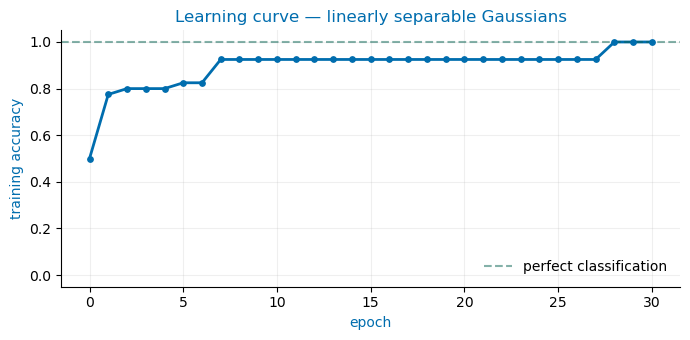

In [7]:
plot_learning_curve(acc_history,
                    title="Learning curve — linearly separable Gaussians")

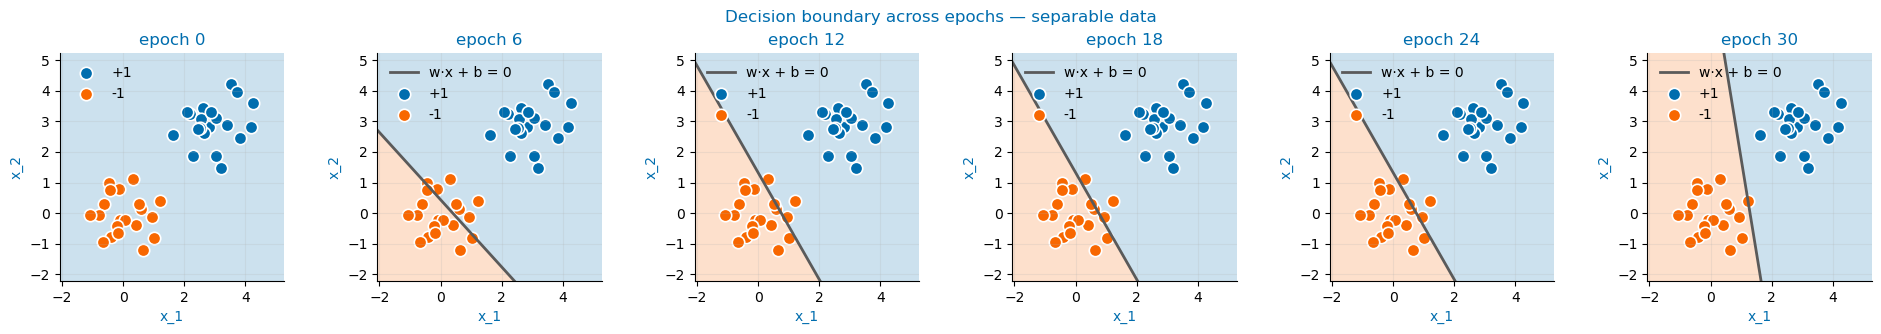

In [8]:
plot_boundary_evolution(
    SEPARABLE_POINTS, SEPARABLE_LABELS,
    snapshots,
    title="Decision boundary across epochs — separable data"
)

---

## D3.3: Run on XOR

XOR is the iconic counterexample. The 4 points are arranged at the corners of a unit square, with diagonally-opposite corners sharing a label. **No straight line can separate the two classes**, and a single-layer perceptron can only draw straight lines. So no matter how long you train, the model never reaches 100% accuracy.

Train your perceptron on XOR for **at least 100 epochs** and observe non-convergence. Plot the learning curve.

In [9]:
# Train on XOR
w_xor, b_xor, acc_xor, snapshots_xor = train_perceptron(
    XOR_POINTS, XOR_LABELS,
    n_epochs=100, learning_rate=1.0, seed=0
)

print(f"Final accuracy: {acc_xor[-1]:.3f}")
print(f"Min accuracy:   {min(acc_xor):.3f}")
print(f"Max accuracy:   {max(acc_xor):.3f}")
print(f"Epochs at 100%: {sum(1 for a in acc_xor if a == 1.0)} / {len(acc_xor)}")
print()
print("Expected: max accuracy never reaches 1.0 — XOR is not linearly separable.")

Final accuracy: 0.500
Min accuracy:   0.250
Max accuracy:   0.750
Epochs at 100%: 0 / 101

Expected: max accuracy never reaches 1.0 — XOR is not linearly separable.


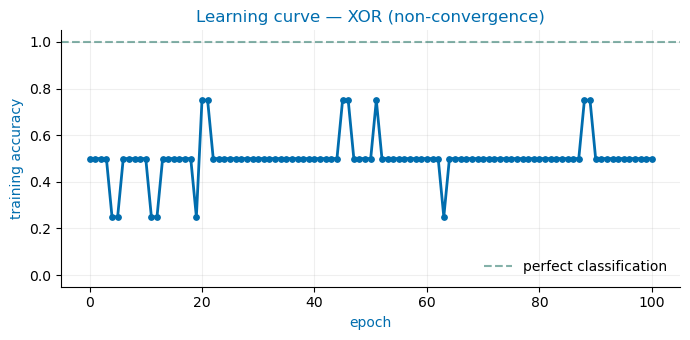

In [10]:
plot_learning_curve(acc_xor, title="Learning curve — XOR (non-convergence)")

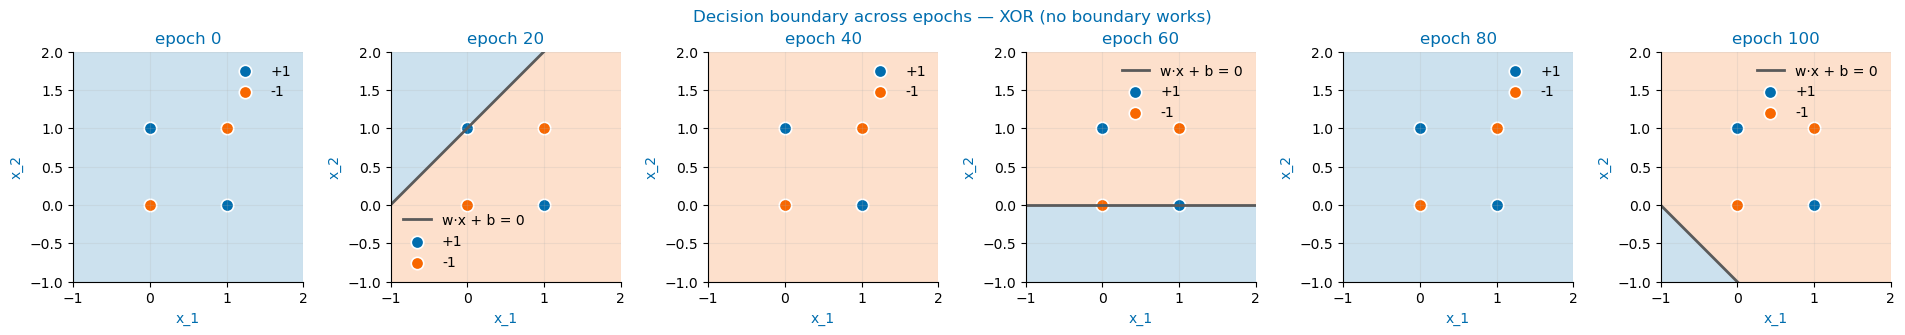

In [11]:
# Snapshot a few epochs' boundaries — see them flailing around.
plot_boundary_evolution(
    XOR_POINTS, XOR_LABELS,
    snapshots_xor,
    title="Decision boundary across epochs — XOR (no boundary works)"
)

---

## D3.4: Explain why (300-500 words)

Write a 300-500 word explanation of **why** a single-layer perceptron cannot learn XOR.

Cover all of the following:

1. **Linear separability.** What does it mean for a dataset to be linearly separable in 2D? Use a small diagram or describe one in words.
2. **Why XOR is not linearly separable.** Show (geometrically or by direct argument) that no single line can separate the four XOR corners into the correct two classes.
3. **What the bias does (and doesn't do).** The bias $b$ shifts the line off the origin. Why doesn't adding a bias rescue the perceptron on XOR?
4. **What would be needed to learn XOR.** Sketch one option: an additional hidden layer, a non-linear feature transformation (e.g. add the feature $x_1 \cdot x_2$), or a kernel trick. Pick one and explain in 2-3 sentences why it works.

This explanation is graded on engagement with the *geometric* reason, not just on stating "XOR is not linearly separable" as a fact.

> _Your explanation here._
>
> _Paragraph 1: A dataset is linearly separable in 2D space if there is one single linear line to separate the space, with all positive (+1) points on one side and all negative (-1) points on the other side. Geometrically, linear separable corresponds to having one straight fence that divides the +1 points from the -1 points, without allowing any of the wrong shape to be inside on either side. A single-layer perceptron's decision rule mathematically forms a straight line, it can learn and converge only on linearly separable datasets.
>
> _Paragraph 2: This is broken by the XOR dataset in the case of spatial geometry. The +1 points are at (0, 1) and (1, 0) in the XOR problem, opposite corners of a square. The -1 points sit at (0, 0) and (1, 1), forming the opposing diagonal. These classes are interleaved along the diagonals, so that any straight line that is drawn to cluster the +1 corners together will at least always have one -1 corner on the wrong side. Consequently, in the training loop, the boundary line will continually hop up and down around the square, ending up in a loop of its own, rescuing one misclassified point and leaving another one behind, and will never reache 100% accuracy.
>
> _Paragraph 3: It is easy to assume that this problem can be solved by simply changing the bias b. The bias, however, only moves the decision boundary towards or away from the origin; the weights rotate the angle of the line. They both move a straight line together around the plane. The basic issue is that there is no geometric remedy for XOR, that is, there is no straight line that can rescue it; neither can a shift with a bias.
>
> _Paragraph 4: In order to be learnable, the model needs to leave the bounds of a single straight line . A good solution is to add a third feature also, but this time an interaction of multiple of the first two, (x_1 x_2). These 2D points are now raised to 3D space, resulting in the now-interleaved corners being moved to completely new planes. In this enriched three dimensional space, the data is again linearly separable and a simple linear classifier can separate the classes easily with a flat plane in the space.


---

## Check your understanding

Run the cell below and answer the quick quiz. The quiz does not grade your work; it's a self-check before you submit.

In [12]:
from jupyterquiz import display_quiz

d3_quiz = [
    {
        "question": "With labels in {-1, +1}, the perceptron update is w ← w + η(y - ŷ)x. What is (y - ŷ) when the prediction is correct?",
        "type": "multiple_choice",
        "answers": [
            {"answer": "0 — both y and ŷ have the same value, so the difference is 0 and no update happens.", "correct": True,
             "feedback": "Correct. The perceptron only updates on errors. (y - ŷ) is 0 on correct predictions and ±2 on errors."},
            {"answer": "+1 — the model gets a small reward for being right.", "correct": False,
             "feedback": "No. The perceptron rule does NOT reward correctness — it only corrects errors. (y - ŷ) is 0 when they agree."},
            {"answer": "-1 or +1 depending on the class.", "correct": False,
             "feedback": "No. (y - ŷ) is 0 when prediction matches label, regardless of which class."},
            {"answer": "It depends on the value of x.", "correct": False,
             "feedback": "No. (y - ŷ) depends only on the prediction and the label, not on the input."},
        ],
    },
    {
        "question": "Why does a single-layer perceptron fail on XOR?",
        "type": "multiple_choice",
        "answers": [
            {"answer": "Because XOR is not linearly separable — no single straight line in the plane can put diagonally-opposite corners on the same side.", "correct": True,
             "feedback": "Correct. The perceptron decision rule is sign(w·x + b), which describes a hyperplane. In 2D that's a line. XOR's diagonal class layout cannot be separated by any line."},
            {"answer": "Because there are only 4 training examples — not enough data.", "correct": False,
             "feedback": "No. Even with infinite copies of those 4 points, the perceptron still couldn't solve it. The issue is geometric, not statistical."},
            {"answer": "Because the learning rate is too large.", "correct": False,
             "feedback": "No. No learning rate can make a linear classifier learn a non-linearly-separable dataset. The issue is the model class, not the optimisation."},
            {"answer": "Because the bias term is missing.", "correct": False,
             "feedback": "No. A bias shifts the line off the origin but does not change its shape. The line is still a line — and no line can separate XOR's diagonal layout."},
        ],
    },
    {
        "question": "Which of these would make XOR learnable by a (suitably extended) linear classifier?",
        "type": "multiple_choice",
        "answers": [
            {"answer": "Add the feature x_1 * x_2 (a non-linear transformation), then a linear classifier on the 3D feature space (x_1, x_2, x_1·x_2) can separate XOR.", "correct": True,
             "feedback": "Correct. In the 3D space (x_1, x_2, x_1·x_2) the four XOR points become (0,0,0), (0,1,0), (1,0,0), (1,1,1). The label-1 corners and label-(-1) corners now lie in different planes — and a single linear classifier can separate them. This is the kernel-trick intuition."},
            {"answer": "Use more training epochs.", "correct": False,
             "feedback": "No. The perceptron convergence theorem only applies to linearly separable data. More epochs on XOR just keeps oscillating."},
            {"answer": "Use a smaller learning rate.", "correct": False,
             "feedback": "No. The learning rate controls step size, not the model's expressive power. No rate can make a linear classifier non-linear."},
            {"answer": "Use a larger bias.", "correct": False,
             "feedback": "No. The bias is just a shift. The decision boundary remains a line."},
        ],
    },
]

display_quiz(d3_quiz, shuffle_answers=True)

<IPython.core.display.Javascript object>

---

## Submission checklist

- [ ] **D3.1:** `predict_all` and `train_perceptron` implemented.
- [ ] **D3.2:** Perceptron converges on `SEPARABLE_POINTS` (accuracy reaches 1.0).
- [ ] **D3.2:** Learning curve plotted.
- [ ] **D3.2:** Boundary evolution plotted (4-6 epochs).
- [ ] **D3.3:** XOR experiment run for ≥100 epochs; non-convergence shown.
- [ ] **D3.3:** XOR learning curve plotted (oscillating around chance).
- [ ] **D3.4:** 300-500 word geometric explanation written.
- [ ] Quiz completed.
- [ ] All files uploaded to OnTrack.
- [ ] Task marked as **Ready for Feedback**.

---

> **AI use policy (Distinction level):**
> Used Copilot to summarize the concept after reading the supplement. The prompt: "lets talk about linear unseperable xor classifiers. the way they work is by adding another dimension, so dumbed down we're changing a 2d graph to 3d?"

---

*FIT1061 Distinction Task 3: Perceptron Training: XOR and Visualisation*